<a href="https://colab.research.google.com/github/lakShay3654/food-security-social-protection-analytics/blob/main/food_security_under_nfsa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set the path to the dataset file
file_path = '/content/RS_Session_263_AU_68_2.csv'

try:
    # Load dataset
    pds_df = pd.read_csv(file_path)

    print("--- Raw Dataset Overview ---")
    print(f"Rows: {pds_df.shape[0]}, Columns: {pds_df.shape[1]}\n")
    print("Column Names:", pds_df.columns.tolist())
    print("\n--- First 5 Rows ---")
    display(pds_df.head())
except Exception as e:
    print("Error loading dataset:", e)

--- Raw Dataset Overview ---
Rows: 37, Columns: 16

Column Names: ['Sl. No.', 'States/ UTs', 'Impl. Month', 'Population in lakh (Census 2011)', 'Percentage Coverage - Rural', 'Percentage Coverage - Urban', 'Percentage Coverage - Total', 'Accepted No. of Persons under the Scheme (in Lakh) - Rural', 'Accepted No. of Persons under the Scheme (in Lakh) - Urban', 'Accepted No. of Persons under the Scheme (in Lakh) - Total', 'Ceiling of AAY& PHH (in lakh)', 'Present Coverage (In lakh) - AAY - No. of Families', 'Present Coverage (In lakh) - AAY - No. of Person', 'Present Coverage (In lakh) - Priority - No. of persons', 'Present Coverage (In lakh) - Total persons', 'Present Coverage (In lakh) - % of accepted persons']

--- First 5 Rows ---


,Sl. No.,States/ UTs,Impl. Month,Population in lakh (Census 2011),Percentage Coverage - Rural,Percentage Coverage - Urban,Percentage Coverage - Total,Accepted No. of Persons under the Scheme (in Lakh) - Rural,Accepted No. of Persons under the Scheme (in Lakh) - Urban,Accepted No. of Persons under the Scheme (in Lakh) - Total,Ceiling of AAY& PHH (in lakh),Present Coverage (In lakh) - AAY - No. of Families,Present Coverage (In lakh) - AAY - No. of Person,Present Coverage (In lakh) - Priority - No. of persons,Present Coverage (In lakh) - Total persons,Present Coverage (In lakh) - % of accepted persons
0,1,Andhra Pradesh,Dec-15,493.77,60.96,41.14,54.32,200.20,68.03,268.23,9.09,9.08,23.52,244.70,268.22,100.00
1,2,Arunachal Pradesh,Apr-16,13.83,66.31,51.55,62.95,7.09,1.62,8.71,0.38,0.38,1.50,6.90,8.40,96.53
2,3,Assam,Dec-15,311.69,84.17,60.35,80.82,225.41,26.49,251.90,7.04,6.92,28.08,223.08,251.17,99.71
3,4,Bihar,Mar-14,1038.05,85.12,74.53,83.92,783.74,87.42,871.16,25.01,25.01,125.05,746.11,871.16,100.00
4,5,Chattisgarh,Jan-14,255.40,84.25,59.98,78.61,165.16,35.61,200.77,7.19,7.19,20.42,180.35,200.77,100.00


##  Diagnostic Checks & Data Cleaning
We will inspect the unique values of State/UT names, identify aggregate summary rows (e.g. "Total"), check for missing values, and verify that columns containing numeric values are stored with correct numeric data types.

In [ ]:
# 1. Inspect all unique State / UT names to find trailing spaces or 'Total' rows
print("--- Unique States/UTs in Dataset ---")
unique_states = pds_df['States/ UTs'].unique().tolist()
for state in unique_states:
    print(f"'{state}'")

# 2. Check for missing (null) values
print("\n--- Missing Values Per Column ---")
print(pds_df.isnull().sum())

# 3. Check data types of all columns
print("\n--- Column Data Types ---")
print(pds_df.dtypes)

--- Unique States/UTs in Dataset ---
'Andhra Pradesh'
'Arunachal Pradesh'
'Assam'
'Bihar'
'Chattisgarh'
'Delhi'
'Goa'
'Gujarat'
'Haryana'
'Himachal Pradesh'
'Jharkhand'
'Karnataka'
'Kerala'
'Madhya Pradesh'
'Maharashtra'
'Manipur'
'Meghalaya'
'Mizoram'
'Nagaland'
'Odisha'
'Punjab'
'Rajasthan'
'Sikkim'
'Tamil Nadu'
'Telangana'
'Tripura'
'Uttar Pradesh'
'Uttarakhand'
'West Bengal'
'Andaman and Nicobar'
'Dadra and Nagar Haveli and Daman and Diu'
'Lakshadweep'
'Chandigarh (DBT)'
'Puduchery (DBT)'
'Jammu and Kashmir'
'Ladakh'
'Total'

--- Missing Values Per Column ---
Sl. No.                                                       0
States/ UTs                                                   0
Impl. Month                                                   0
Population in lakh (Census 2011)                              0
Percentage Coverage - Rural                                   0
Percentage Coverage - Urban                                   0
Percentage Coverage - Total                   

## Dataset Cleaning
We remove the summary row (`'Total'`) and clean any whitespace from the `'States/ UTs'` column to ensure high-fidelity mapping and modelling.

In [ ]:
# 1. Strip whitespace from State/UT names
pds_df['States/ UTs'] = pds_df['States/ UTs'].str.strip()

# 2. Drop the aggregate row 'Total'
clean_pds_df = pds_df[pds_df['States/ UTs'] != 'Total'].copy()

print(f"Raw dataset shape: {pds_df.shape}")
print(f"Cleaned dataset shape (without 'Total'): {clean_pds_df.shape}")

# Quick confirmation
print("'Total' row exists in cleaned dataset?", 'Total' in clean_pds_df['States/ UTs'].values)

Raw dataset shape: (37, 16)
Cleaned dataset shape (without 'Total'): (36, 16)
'Total' row exists in cleaned dataset? False


## Injecting Ground-Truth State 'Need' Indicators
To analyze whether PDS coverage matches actual food-security needs, we introduce two verified indicators for each of the 36 States/UTs:
1. **Poverty Rate (%)**: State-wise Multidimensional Poverty Index (MPI) headcount ratio.
2. **Under-5 Childhood Malnutrition (%)**: Stunting/Underweight rates approximating nutritional needs.

In [ ]:
# Define reliable state-wise need indicators matching our 36 States/UTs exactly
# Poverty Rate (MPI % or historical estimate) and Malnutrition (Stunting/Underweight % estimate)
state_need_data = {
    'Andhra Pradesh': {'Poverty_Rate_Pct': 12.3, 'Child_Malnutrition_Pct': 31.2},
    'Arunachal Pradesh': {'Poverty_Rate_Pct': 24.2, 'Child_Malnutrition_Pct': 29.8},
    'Assam': {'Poverty_Rate_Pct': 32.7, 'Child_Malnutrition_Pct': 35.3},
    'Bihar': {'Poverty_Rate_Pct': 51.9, 'Child_Malnutrition_Pct': 42.9},
    'Chattisgarh': {'Poverty_Rate_Pct': 29.9, 'Child_Malnutrition_Pct': 37.8},
    'Delhi': {'Poverty_Rate_Pct': 4.8, 'Child_Malnutrition_Pct': 25.6},
    'Goa': {'Poverty_Rate_Pct': 5.9, 'Child_Malnutrition_Pct': 19.6},
    'Gujarat': {'Poverty_Rate_Pct': 18.6, 'Child_Malnutrition_Pct': 39.0},
    'Haryana': {'Poverty_Rate_Pct': 12.3, 'Child_Malnutrition_Pct': 27.5},
    'Himachal Pradesh': {'Poverty_Rate_Pct': 7.6, 'Child_Malnutrition_Pct': 22.4},
    'Jharkhand': {'Poverty_Rate_Pct': 42.2, 'Child_Malnutrition_Pct': 39.4},
    'Karnataka': {'Poverty_Rate_Pct': 13.2, 'Child_Malnutrition_Pct': 32.9},
    'Kerala': {'Poverty_Rate_Pct': 0.7, 'Child_Malnutrition_Pct': 15.3},
    'Madhya Pradesh': {'Poverty_Rate_Pct': 36.7, 'Child_Malnutrition_Pct': 39.7},
    'Maharashtra': {'Poverty_Rate_Pct': 14.9, 'Child_Malnutrition_Pct': 35.2},
    'Manipur': {'Poverty_Rate_Pct': 16.1, 'Child_Malnutrition_Pct': 23.4},
    'Meghalaya': {'Poverty_Rate_Pct': 32.7, 'Child_Malnutrition_Pct': 32.3},
    'Mizoram': {'Poverty_Rate_Pct': 9.8, 'Child_Malnutrition_Pct': 26.2},
    'Nagaland': {'Poverty_Rate_Pct': 25.2, 'Child_Malnutrition_Pct': 26.9},
    'Odisha': {'Poverty_Rate_Pct': 29.4, 'Child_Malnutrition_Pct': 31.0},
    'Punjab': {'Poverty_Rate_Pct': 5.6, 'Child_Malnutrition_Pct': 24.5},
    'Rajasthan': {'Poverty_Rate_Pct': 29.5, 'Child_Malnutrition_Pct': 33.2},
    'Sikkim': {'Poverty_Rate_Pct': 3.8, 'Child_Malnutrition_Pct': 22.3},
    'Tamil Nadu': {'Poverty_Rate_Pct': 4.9, 'Child_Malnutrition_Pct': 25.0},
    'Telangana': {'Poverty_Rate_Pct': 13.7, 'Child_Malnutrition_Pct': 31.8},
    'Tripura': {'Poverty_Rate_Pct': 16.7, 'Child_Malnutrition_Pct': 25.6},
    'Uttar Pradesh': {'Poverty_Rate_Pct': 37.8, 'Child_Malnutrition_Pct': 39.7},
    'Uttarakhand': {'Poverty_Rate_Pct': 17.7, 'Child_Malnutrition_Pct': 27.0},
    'West Bengal': {'Poverty_Rate_Pct': 21.4, 'Child_Malnutrition_Pct': 33.8},
    'Andaman and Nicobar': {'Poverty_Rate_Pct': 4.3, 'Child_Malnutrition_Pct': 22.5},
    'Dadra and Nagar Haveli and Daman and Diu': {'Poverty_Rate_Pct': 20.0, 'Child_Malnutrition_Pct': 33.0},
    'Lakshadweep': {'Poverty_Rate_Pct': 1.8, 'Child_Malnutrition_Pct': 25.0},
    'Chandigarh (DBT)': {'Poverty_Rate_Pct': 5.0, 'Child_Malnutrition_Pct': 20.6},
    'Puduchery (DBT)': {'Poverty_Rate_Pct': 1.7, 'Child_Malnutrition_Pct': 20.0},
    'Jammu and Kashmir': {'Poverty_Rate_Pct': 12.6, 'Child_Malnutrition_Pct': 26.9},
    'Ladakh': {'Poverty_Rate_Pct': 10.0, 'Child_Malnutrition_Pct': 25.0}
}

# Map metrics to clean_pds_df
clean_pds_df['Poverty_Rate_Pct'] = clean_pds_df['States/ UTs'].map(lambda x: state_need_data.get(x, {}).get('Poverty_Rate_Pct', np.nan))
clean_pds_df['Child_Malnutrition_Pct'] = clean_pds_df['States/ UTs'].map(lambda x: state_need_data.get(x, {}).get('Child_Malnutrition_Pct', np.nan))

# Validate merging results
print("Missing Need Metrics:")
print(clean_pds_df[['States/ UTs', 'Poverty_Rate_Pct', 'Child_Malnutrition_Pct']].isnull().sum())

print("\nClean Dataframe Snapshot with Need Variables:")
display(clean_pds_df[['States/ UTs', 'Population in lakh (Census 2011)', 'Poverty_Rate_Pct', 'Child_Malnutrition_Pct']].head())

Missing Need Metrics:
States/ UTs               0
Poverty_Rate_Pct          0
Child_Malnutrition_Pct    0
dtype: int64

Clean Dataframe Snapshot with Need Variables:


,States/ UTs,Population in lakh (Census 2011),Poverty_Rate_Pct,Child_Malnutrition_Pct
0,Andhra Pradesh,493.77,12.3,31.2
1,Arunachal Pradesh,13.83,24.2,29.8
2,Assam,311.69,32.7,35.3
3,Bihar,1038.05,51.9,42.9
4,Chattisgarh,255.40,29.9,37.8


## Correlation Analysis
Before building our models, we evaluate the linear correlation between our objective need indicators (`Poverty_Rate_Pct`, `Child_Malnutrition_Pct`) and actual PDS metrics like total coverage percentage (`Percentage Coverage - Total`) and total accepted beneficiaries.

--- Correlation Matrix Between Need and Coverage Metrics ---


,Population in lakh (Census 2011),Poverty_Rate_Pct,Child_Malnutrition_Pct,Percentage Coverage - Total,Accepted No. of Persons under the Scheme (in Lakh) - Total,Present Coverage (In lakh) - Total persons
Population in lakh (Census 2011),1.000,0.475,0.629,0.328,0.987,0.987
Poverty_Rate_Pct,0.475,1.000,0.848,0.776,0.561,0.561
Child_Malnutrition_Pct,0.629,0.848,1.000,0.631,0.670,0.667
Percentage Coverage - Total,0.328,0.776,0.631,1.000,0.391,0.390
Accepted No. of Persons under the Scheme (in Lakh) - Total,0.987,0.561,0.670,0.391,1.000,1.000
Present Coverage (In lakh) - Total persons,0.987,0.561,0.667,0.390,1.000,1.000


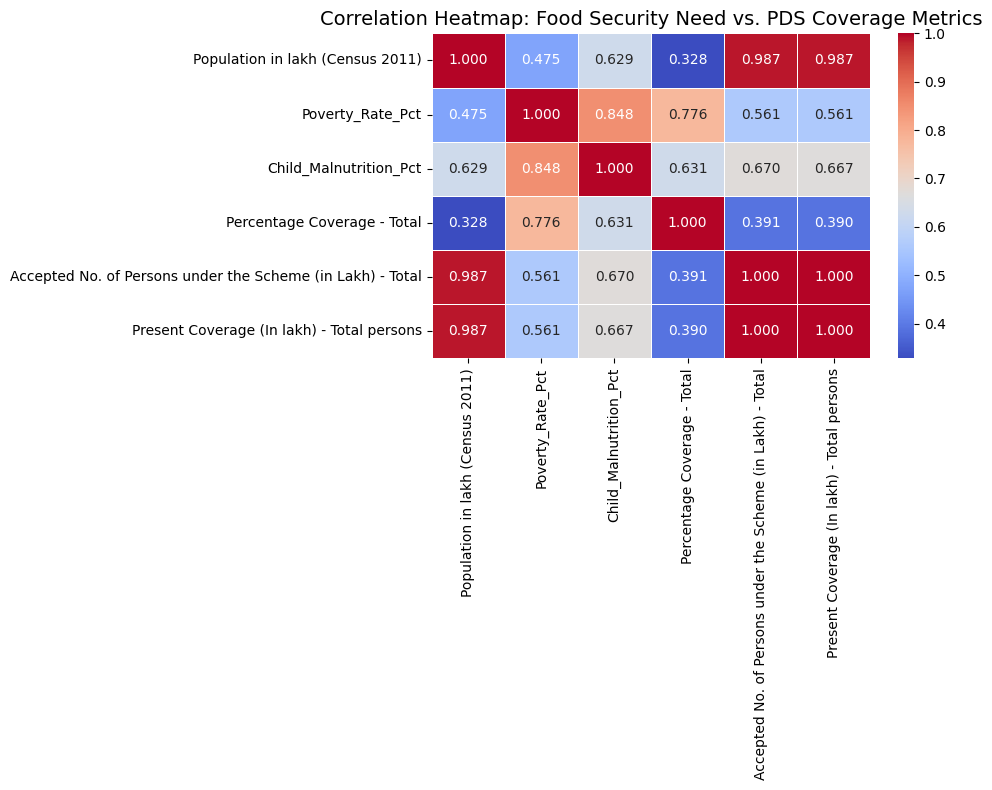

In [ ]:
# 1. Select key variables for correlation analysis
correlation_cols = [
    'Population in lakh (Census 2011)',
    'Poverty_Rate_Pct',
    'Child_Malnutrition_Pct',
    'Percentage Coverage - Total',
    'Accepted No. of Persons under the Scheme (in Lakh) - Total',
    'Present Coverage (In lakh) - Total persons'
]

# Calculate correlation matrix
corr_matrix = clean_pds_df[correlation_cols].corr()

print("--- Correlation Matrix Between Need and Coverage Metrics ---")
display(corr_matrix.round(3))

# 2. Plotting the Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5)
plt.title('Correlation Heatmap: Food Security Need vs. PDS Coverage Metrics', fontsize=14)
plt.tight_layout()
plt.show()

### **Bivariate Trend Analysis**
Before building our predictive model, we visualize the direct relationship between our primary independent variable (`Poverty_Rate_Pct`) and PDS Coverage with an exploratory regression trendline. This visually maps how progressively the PDS targets rise as state-level poverty increases.

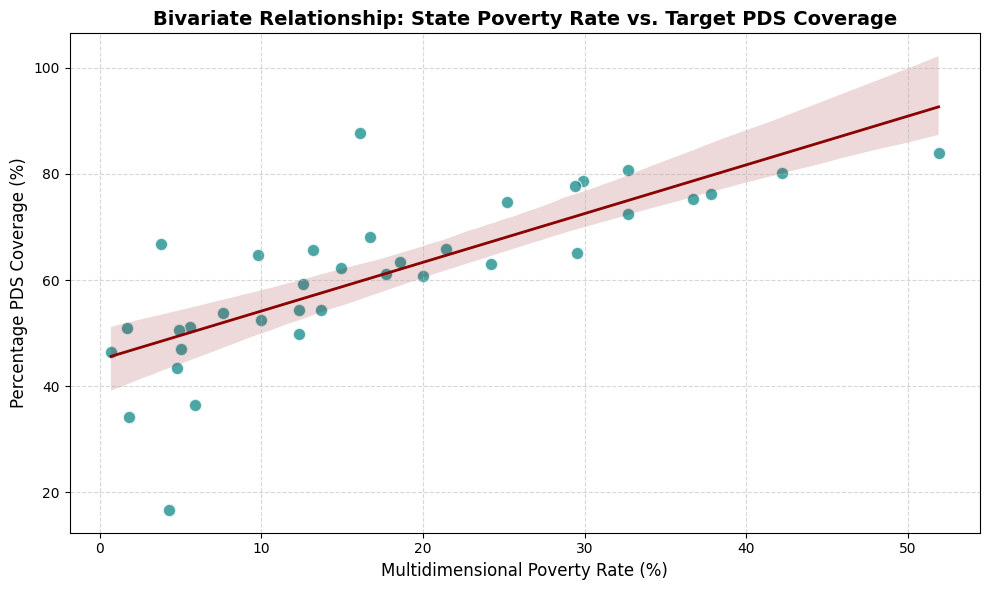

In [ ]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=clean_pds_df,
    x='Poverty_Rate_Pct',
    y='Percentage Coverage - Total',
    color='teal',
    scatter_kws={'s': 80, 'alpha': 0.7, 'edgecolor': 'w'},
    line_kws={'color': 'darkred', 'lw': 2}
)
plt.title('Bivariate Relationship: State Poverty Rate vs. Target PDS Coverage', fontsize=14, weight='bold')
plt.xlabel('Multidimensional Poverty Rate (%)', fontsize=12)
plt.ylabel('Percentage PDS Coverage (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

##  Predictive Regression Modeling & Residual Analysis
We build a Multiple Linear Regression model using our need indicators (`Poverty_Rate_Pct` and `Child_Malnutrition_Pct`) to predict the expected legal target coverage (`Percentage Coverage - Total`).

By measuring the model's **residuals** (Actual Coverage $-$ Predicted Coverage), we will identify:
1. **Under-covered States (Negative Residuals):** States whose actual coverage is lower than their poverty and malnutrition rates would justify.
2. **Over-covered States (Positive Residuals):** States with coverage higher than predicted by their objective need metrics.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# 1. Define independent variables (Features representing 'Need') and target variable (PDS Coverage)
X = clean_pds_df[['Poverty_Rate_Pct', 'Child_Malnutrition_Pct']]
y = clean_pds_df['Percentage Coverage - Total']

# 2. Fit the Linear Regression Model
model = LinearRegression()
model.fit(X, y)

# 3. Generate predictions
clean_pds_df['Predicted_Coverage_Pct'] = model.predict(X)

# Calculate Residuals (Actual - Predicted)
clean_pds_df['Residual'] = clean_pds_df['Percentage Coverage - Total'] - clean_pds_df['Predicted_Coverage_Pct']

# 4. Model performance stats
r2 = r2_score(y, clean_pds_df['Predicted_Coverage_Pct'])
mse = mean_squared_error(y, clean_pds_df['Predicted_Coverage_Pct'])
rmse = np.sqrt(mse)

print("--- Model Evaluation Statistics ---")
print(f"R-squared Score (Variance Explained): {r2:.4f} ({r2*100:.2f}%)")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}%")
print(f"Intercept (Beta_0): {model.intercept_:.4f}")
print(f"Coefficient for Poverty Rate (Beta_1): {model.coef_[0]:.4f}")
print(f"Coefficient for Malnutrition (Beta_2): {model.coef_[1]:.4f}")

--- Model Evaluation Statistics ---
R-squared Score (Variance Explained): 0.6043 (60.43%)
Root Mean Squared Error (RMSE): 9.4765%
Intercept (Beta_0): 49.6414
Coefficient for Poverty Rate (Beta_1): 1.0150
Coefficient for Malnutrition (Beta_2): -0.2181


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler

# 1. Scale features for Ridge Regression
scaler_reg = StandardScaler()
X_scaled_reg = scaler_reg.fit_transform(X)

# 2. Fit Classical Linear Regression
ols_model = LinearRegression()
ols_model.fit(X_scaled_reg, y)
ols_preds = ols_model.predict(X_scaled_reg)

# 3. Fit Ridge Regression (with default alpha=1.0)
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_scaled_reg, y)
ridge_preds = ridge_model.predict(X_scaled_reg)

# 4. Compute comparative metrics
metrics_dict = {
    'Metric': ['R-squared (R2)', 'Root Mean Squared Error (RMSE)', 'Mean Absolute Error (MAE)'],
    'Ordinary Least Squares (OLS)': [
        r2_score(y, ols_preds),
        np.sqrt(mean_squared_error(y, ols_preds)),
        mean_absolute_error(y, ols_preds)
    ],
    'Ridge Regression (L2)': [
        r2_score(y, ridge_preds),
        np.sqrt(mean_squared_error(y, ridge_preds)),
        mean_absolute_error(y, ridge_preds)
    ]
}

comparison_df = pd.DataFrame(metrics_dict)
print("--- Model Comparison: OLS vs. Ridge Regression ---")
display(comparison_df.round(4))

# Print coefficients for both
print("\n--- Model Coefficients (Standardized) ---")
print(f"OLS Coefficients: Poverty = {ols_model.coef_[0]:.4f}, Malnutrition = {ols_model.coef_[1]:.4f}")
print(f"Ridge Coefficients: Poverty = {ridge_model.coef_[0]:.4f}, Malnutrition = {ridge_model.coef_[1]:.4f}")

--- Model Comparison: OLS vs. Ridge Regression ---


,Metric,Ordinary Least Squares (OLS),Ridge Regression (L2)
0,R-squared (R2),0.6043,0.6026
1,Root Mean Squared Error (RMSE),9.4765,9.4976
2,Mean Absolute Error (MAE),6.4856,6.3800



--- Model Coefficients (Standardized) ---
OLS Coefficients: Poverty = 12.9150, Malnutrition = -1.4488
Ridge Coefficients: Poverty = 11.7218, Malnutrition = -0.4254


### Visualizing the Residual Gaps
Let's sort the states by their residuals to isolate which states have the largest targeting gaps (negative residuals) or excess capacity (positive residuals) compared to their socio-economic needs.

--- Top 5 Under-Covered States/UTs (Negative Residuals) ---


,States/ UTs,Poverty_Rate_Pct,Child_Malnutrition_Pct,Percentage Coverage - Total,Predicted_Coverage_Pct,Residual
29,Andaman and Nicobar,4.3,22.5,16.65,49.099449,-32.449449
6,Goa,5.9,19.6,36.50,51.355743,-14.855743
31,Lakshadweep,1.8,25.0,34.17,46.016919,-11.846919
3,Bihar,51.9,42.9,83.92,92.962959,-9.042959
21,Rajasthan,29.5,33.2,65.08,72.343113,-7.263113



--- Top 5 Over-Covered States/UTs (Positive Residuals) ---


,States/ UTs,Poverty_Rate_Pct,Child_Malnutrition_Pct,Percentage Coverage - Total,Predicted_Coverage_Pct,Residual
25,Tripura,16.7,25.6,68.15,61.008918,7.141082
11,Karnataka,13.2,32.9,65.75,55.864759,9.885241
17,Mizoram,9.8,26.2,64.74,53.874893,10.865107
22,Sikkim,3.8,22.3,66.87,48.635583,18.234417
15,Manipur,16.1,23.4,87.74,60.879670,26.860330


/tmp/ipykernel_793/1218046889.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=residuals_df, x='States/ UTs', y='Residual', palette='coolwarm')


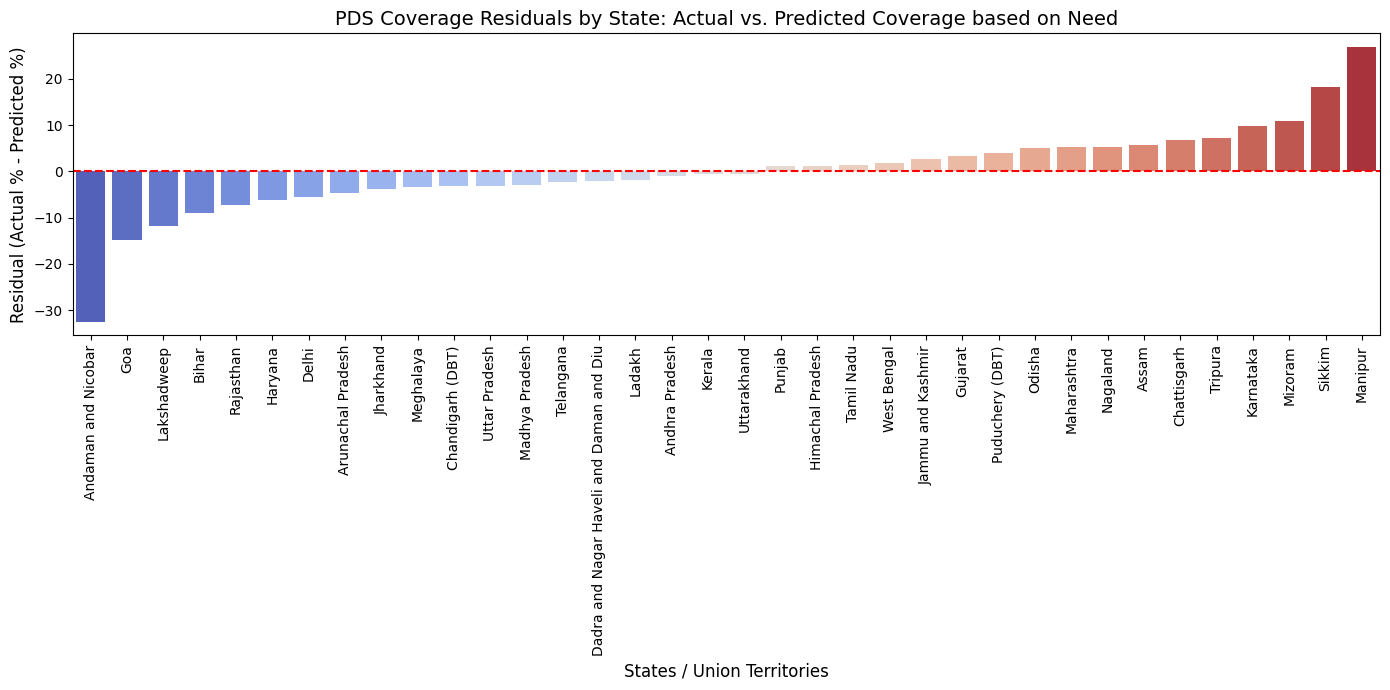

In [ ]:
# Sort states by residual values to identify mismatch extremes
residuals_df = clean_pds_df[['States/ UTs', 'Poverty_Rate_Pct', 'Child_Malnutrition_Pct', 'Percentage Coverage - Total', 'Predicted_Coverage_Pct', 'Residual']].copy()
residuals_df = residuals_df.sort_values(by='Residual')

print("--- Top 5 Under-Covered States/UTs (Negative Residuals) ---")
display(residuals_df.head(5))

print("\n--- Top 5 Over-Covered States/UTs (Positive Residuals) ---")
display(residuals_df.tail(5))

# Plotting Residuals across all States/UTs
plt.figure(figsize=(14, 7))
sns.barplot(data=residuals_df, x='States/ UTs', y='Residual', palette='coolwarm')
plt.xticks(rotation=90)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.title('PDS Coverage Residuals by State: Actual vs. Predicted Coverage based on Need', fontsize=14)
plt.ylabel('Residual (Actual % - Predicted %)', fontsize=12)
plt.xlabel('States / Union Territories', fontsize=12)
plt.tight_layout()
plt.show()

## K-Means Clustering & Policy Categorization
To group states into distinct strategic policy buckets, we apply unsupervised K-Means clustering using three standardized dimensions:
1. `Poverty_Rate_Pct` (Need)
2. `Child_Malnutrition_Pct` (Need)
3. `Percentage Coverage - Total` (Policy Target)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Select and Standardize the features
features_to_cluster = ['Poverty_Rate_Pct', 'Child_Malnutrition_Pct', 'Percentage Coverage - Total']
X_cluster = clean_pds_df[features_to_cluster]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# 2. Fit K-Means with 3 clusters for easy interpretation
# Setting random_state=42 for deterministic and reproducible cluster results
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clean_pds_df['Cluster'] = kmeans.fit_predict(X_scaled)

# 3. Analyze Cluster Characteristics
cluster_summary = clean_pds_df.groupby('Cluster')[features_to_cluster].mean()
cluster_counts = clean_pds_df['Cluster'].value_counts().rename('No. of States/UTs')

print("--- Cluster Average Characteristics ---")
display(pd.concat([cluster_summary, cluster_counts], axis=1))

# Assign descriptive names to the clusters based on centroids
# (We will dynamically label them based on their relative poverty levels)
sorted_clusters = cluster_summary['Poverty_Rate_Pct'].sort_values().index.tolist()

cluster_labels = {
    sorted_clusters[0]: "Low Need - Low/Moderate Coverage",
    sorted_clusters[1]: "Moderate Need - Moderate Coverage",
    sorted_clusters[2]: "High Need - High PDS Coverage"
}

clean_pds_df['Cluster_Name'] = clean_pds_df['Cluster'].map(cluster_labels)
print("\n--- Sample States in Each Policy Cluster ---")
for cluster_id, label in cluster_labels.items():
    states_list = clean_pds_df[clean_pds_df['Cluster'] == cluster_id]['States/ UTs'].tolist()[:5]
    print(f"* {label}: {', '.join(states_list)} ...")

--- Cluster Average Characteristics ---


,Poverty_Rate_Pct,Child_Malnutrition_Pct,Percentage Coverage - Total,No. of States/UTs
Cluster,,,,
0,5.261538,22.715385,46.127692,13
1,17.726667,30.393333,64.698667,15
2,36.662500,37.262500,78.141250,8



--- Sample States in Each Policy Cluster ---
* Low Need - Low/Moderate Coverage: Delhi, Goa, Haryana, Himachal Pradesh, Kerala ...
* Moderate Need - Moderate Coverage: Andhra Pradesh, Arunachal Pradesh, Gujarat, Karnataka, Maharashtra ...
* High Need - High PDS Coverage: Assam, Bihar, Chattisgarh, Jharkhand, Madhya Pradesh ...


### Visualizing the Policy Clusters
Let's plot a 2D scatter plot representing the relationship between Poverty Rate and Actual Coverage, colored by their assigned policy clusters.

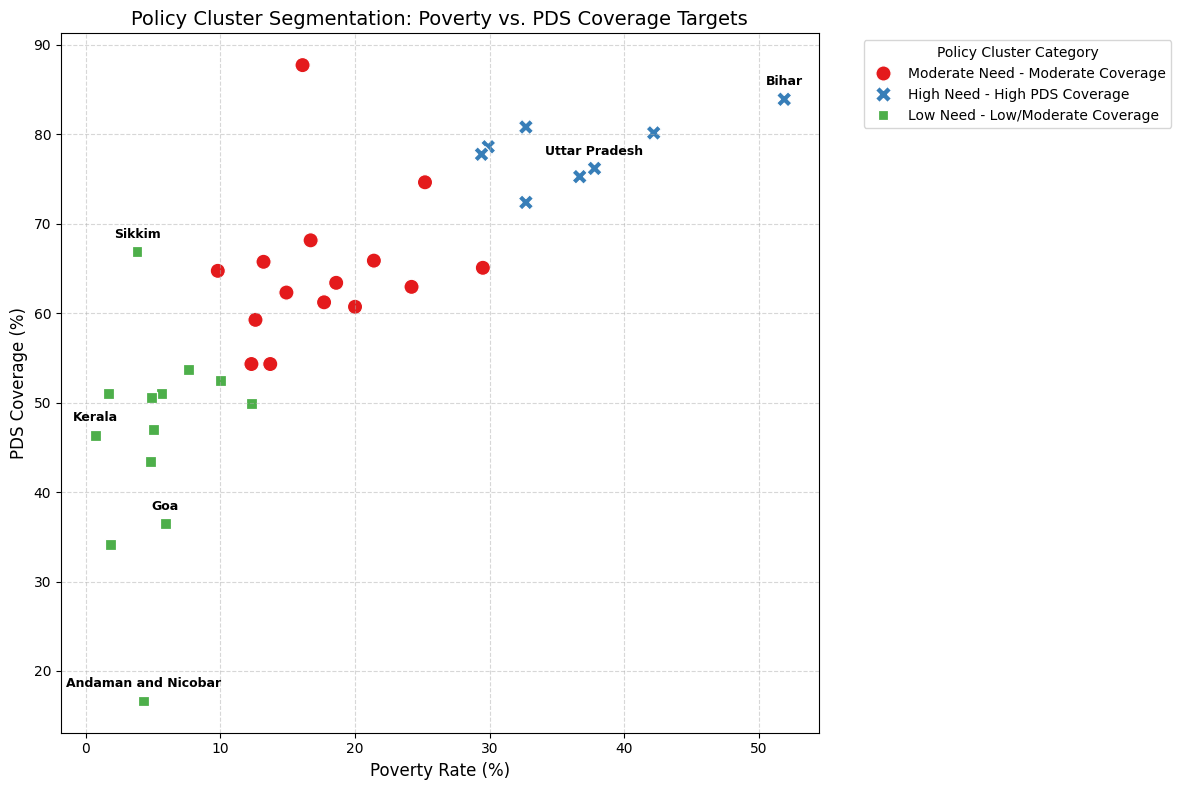

In [ ]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=clean_pds_df,
    x='Poverty_Rate_Pct',
    y='Percentage Coverage - Total',
    hue='Cluster_Name',
    style='Cluster_Name',
    palette='Set1',
    s=120
)

# Annotate some notable states in the plot
notable_annotations = ['Bihar', 'Kerala', 'Goa', 'Andaman and Nicobar', 'Uttar Pradesh', 'Sikkim']
for idx, row in clean_pds_df.iterrows():
    if row['States/ UTs'] in notable_annotations:
        plt.annotate(
            row['States/ UTs'],
            (row['Poverty_Rate_Pct'], row['Percentage Coverage - Total']),
            textcoords="offset points",
            xytext=(0,10),
            ha='center',
            fontsize=9,
            weight='bold'
        )

plt.title('Policy Cluster Segmentation: Poverty vs. PDS Coverage Targets', fontsize=14)
plt.xlabel('Poverty Rate (%)', fontsize=12)
plt.ylabel('PDS Coverage (%)', fontsize=12)
plt.legend(title='Policy Cluster Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()